# JS06 – Regresi: Praktikum 2
## Support Vector Regression (SVR) untuk Prediksi Gaji

**Tujuan praktikum**

1. Memahami mengapa **feature scaling** diperlukan pada SVR.
2. Membangun model **Support Vector Regression** dengan kernel RBF.
3. Memvisualisasikan kurva regresi non-linear pada data gaji berdasarkan level posisi.
4. Memprediksi gaji untuk level posisi 6,5.
5. Mengevaluasi model dengan **MAE, MSE, RMSE, dan R²** dalam satuan gaji asli.

**Dataset:** `Posisi_gaji.csv` berisi 10 level posisi (`Level`) dan gaji (`Gaji`) dalam USD. Hubungan antara level dan gaji jelas non-linear: kenaikan gaji makin besar pada level yang lebih tinggi, terutama dari C-level ke CEO.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membaca dan memahami data

In [2]:
dataset = pd.read_csv("Posisi_gaji.csv")

print("Ukuran data:", dataset.shape)
dataset

Ukuran data: (10, 3)


,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Posisi  10 non-null     str  
 1   Level   10 non-null     int64
 2   Gaji    10 non-null     int64
dtypes: int64(2), str(1)
memory usage: 372.0 bytes


In [4]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Level,10.0,5.5,3.027650,1.0,3.25,5.5,7.75,10.0
Gaji,10.0,249500.0,299373.883668,45000.0,65000.00,130000.0,275000.00,1000000.0


In [5]:
print("Jumlah nilai kosong:")
print(dataset.isna().sum())
print("\nJumlah baris duplikat:", dataset.duplicated().sum())

Jumlah nilai kosong:
Posisi    0
Level     0
Gaji      0
dtype: int64

Jumlah baris duplikat: 0


### 2. Eksplorasi hubungan level posisi dan gaji

Scatter plot berikut memperlihatkan bahwa hubungan antara `Level` dan `Gaji` tidak linear. Perbedaan gaji antarlevel makin besar ketika level mendekati puncak. Pola inilah yang mendorong penggunaan model non-linear seperti SVR dengan kernel RBF.

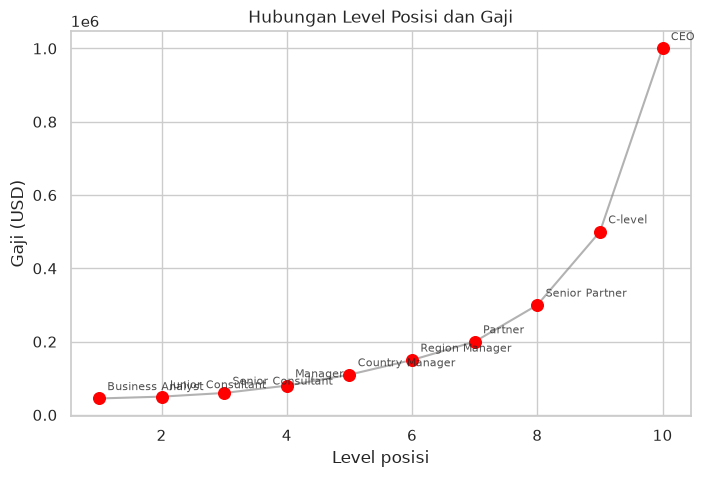

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(dataset["Level"], dataset["Gaji"], color="red", s=70, zorder=3)
plt.plot(dataset["Level"], dataset["Gaji"], color="gray", alpha=0.6, zorder=2)

for _, row in dataset.iterrows():
    plt.annotate(
        row["Posisi"],
        (row["Level"], row["Gaji"]),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=8,
        alpha=0.8,
    )

plt.title("Hubungan Level Posisi dan Gaji")
plt.xlabel("Level posisi")
plt.ylabel("Gaji (USD)")
plt.show()

In [7]:
dataset[["Level", "Gaji"]].corr()

,Level,Gaji
Level,1.000000,0.817949
Gaji,0.817949,1.000000


### 3. Feature scaling

SVR berbasis kernel RBF menghitung jarak antar titik. Tanpa penskalaan, fitur dengan rentang besar (gaji sampai 1.000.000) akan mendominasi perhitungan dan membuat model tidak stabil. `StandardScaler` mengubah setiap variabel menjadi

$$z = \frac{x - \mu}{\sigma},$$

sehingga rata-rata menjadi 0 dan simpangan baku menjadi 1. Pada praktikum ini, **fitur `X` dan target `y` sama-sama diskalakan**. Prediksi kemudian dikembalikan ke skala asli dengan `inverse_transform`.

In [8]:
X = dataset.iloc[:, 1:2].values   # Level
y = dataset.iloc[:, 2].values     # Gaji

sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X)
y_scaled = sc_y.fit_transform(y.reshape(-1, 1)).ravel()

print("Sebelum scaling:")
print("X  min/max:", X.min(), "/", X.max())
print("y  min/max:", y.min(), "/", y.max())
print("\nSetelah scaling:")
print("X  mean/std:", round(X_scaled.mean(), 4), "/", round(X_scaled.std(), 4))
print("y  mean/std:", round(y_scaled.mean(), 4), "/", round(y_scaled.std(), 4))

Sebelum scaling:
X  min/max: 1 / 10
y  min/max: 45000 / 1000000

Setelah scaling:
X  mean/std: -0.0 / 1.0
y  mean/std: -0.0 / 1.0


### 4. Melatih model SVR

Model memakai kernel **RBF (Radial Basis Function)**. Kernel ini memungkinkan SVR menyesuaikan kurva non-linear terhadap data. Parameter yang dipakai adalah nilai default `scikit-learn` (`C=1`, `epsilon=0.1`, `gamma='scale'`) agar sesuai dengan praktikum pada modul.

In [9]:
regressor = SVR(kernel="rbf")
regressor.fit(X_scaled, y_scaled)

print("Model SVR berhasil dilatih.")
print("Jumlah support vector:", len(regressor.support_))

Model SVR berhasil dilatih.
Jumlah support vector: 5


### 5. Visualisasi kurva SVR

Grid level posisi dibuat rapat (resolusi 0,01) agar kurva terlihat halus. Titik merah adalah data asli, sedangkan garis biru adalah prediksi model pada skala asli.

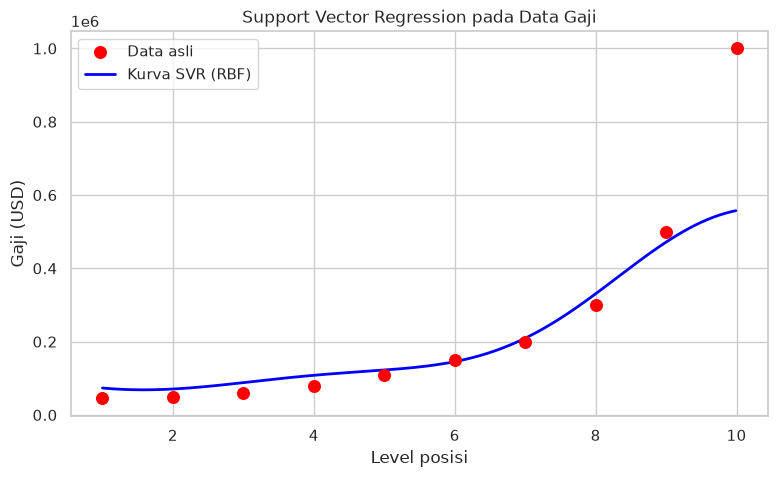

In [10]:
X_grid_scaled = np.arange(X_scaled.min(), X_scaled.max(), 0.01).reshape(-1, 1)
y_grid_scaled = regressor.predict(X_grid_scaled)
y_grid = sc_y.inverse_transform(y_grid_scaled.reshape(-1, 1)).ravel()
X_grid = sc_X.inverse_transform(X_grid_scaled).ravel()

plt.figure(figsize=(9, 5))
plt.scatter(X, y, color="red", s=70, label="Data asli", zorder=3)
plt.plot(X_grid, y_grid, color="blue", linewidth=2, label="Kurva SVR (RBF)")
plt.title("Support Vector Regression pada Data Gaji")
plt.xlabel("Level posisi")
plt.ylabel("Gaji (USD)")
plt.legend()
plt.show()

### 6. Prediksi gaji untuk level posisi 6,5

Nilai baru harus diskalakan dengan `sc_X` yang **sama** seperti saat pelatihan, lalu hasil prediksi dikembalikan ke skala USD dengan `sc_y.inverse_transform`.

In [11]:
tingkat_posisi_prediksi = np.array([[6.5]])
tingkat_posisi_prediksi_scaled = sc_X.transform(tingkat_posisi_prediksi)

gaji_prediksi_scaled = regressor.predict(tingkat_posisi_prediksi_scaled)
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi_scaled.reshape(-1, 1)).ravel()

print("Level posisi 6,5 setara dengan:")
print(dataset.iloc[5]["Posisi"], "sampai", dataset.iloc[6]["Posisi"])
print(f"\nPrediksi gaji: USD {gaji_prediksi[0]:,.2f}")

Level posisi 6,5 setara dengan:
Region Manager sampai Partner

Prediksi gaji: USD 170,370.02


### 7. Evaluasi model

Evaluasi dilakukan pada seluruh data yang dipakai untuk pelatihan (*in-sample*), sesuai alur praktikum pada modul. Prediksi dikembalikan ke skala USD agar MAE, MSE, dan RMSE mudah ditafsirkan. R² tidak berubah terhadap penskalaan, tetapi MAE/RMSE dalam satuan asli jauh lebih informatif.

> **Catatan metodologi:** karena hanya tersedia 10 data dan model dievaluasi pada data yang sama dengan data pelatihan, nilai evaluasi ini bersifat **optimistis**. Pada kasus nyata, gunakan pembagian data latih–uji atau validasi silang.

In [12]:
y_actual = y
y_pred = sc_y.inverse_transform(
    regressor.predict(X_scaled).reshape(-1, 1)
).ravel()

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

evaluasi = pd.DataFrame({
    "Metrik": ["MAE (USD)", "MSE (USD²)", "RMSE (USD)", "R²"],
    "Nilai": [mae, mse, rmse, r2],
})
evaluasi["Nilai"] = evaluasi["Nilai"].map(lambda v: f"{v:,.4f}")
evaluasi

,Metrik,Nilai
0,MAE (USD),"63,332.3921"
1,MSE (USD²),"20,036,494,264.1318"
2,RMSE (USD),"141,550.3241"
3,R²,0.7516


In [13]:
perbandingan = pd.DataFrame({
    "Nilai aktual (USD)": y_actual,
    "Prediksi SVR (USD)": y_pred,
    "Error (USD)": y_actual - y_pred,
})
perbandingan.round(2)

,Nilai aktual (USD),Prediksi SVR (USD),Error (USD)
0,45000,73474.16,-28474.16
1,50000,70786.95,-20786.95
2,60000,88213.01,-28213.01
3,80000,108254.99,-28254.99
4,110000,122574.52,-12574.52
5,150000,145503.11,4496.89
6,200000,209410.23,-9410.23
7,300000,330606.89,-30606.89
8,500000,471671.96,28328.04
9,1000000,557821.76,442178.24


### 8. Perbandingan singkat dengan regresi linier

Untuk melihat manfaat model non-linear, kita bandingkan SVR dengan regresi linier sederhana pada data yang sama. Regresi linier memaksakan satu garis lurus, sedangkan SVR RBF dapat mengikuti percepatan kenaikan gaji pada level tinggi.

In [14]:
linreg = LinearRegression()
linreg.fit(X, y)
y_pred_lin = linreg.predict(X)

perbandingan_model = pd.DataFrame({
    "Model": ["Regresi linier", "SVR (RBF)"],
    "R²": [r2_score(y, y_pred_lin), r2_score(y, y_pred)],
    "RMSE (USD)": [
        np.sqrt(mean_squared_error(y, y_pred_lin)),
        np.sqrt(mean_squared_error(y, y_pred)),
    ],
    "MAE (USD)": [
        mean_absolute_error(y, y_pred_lin),
        mean_absolute_error(y, y_pred),
    ],
})
perbandingan_model.round(2)

,Model,R²,RMSE (USD),MAE (USD)
0,Regresi linier,0.67,163388.74,128454.55
1,SVR (RBF),0.75,141550.32,63332.39


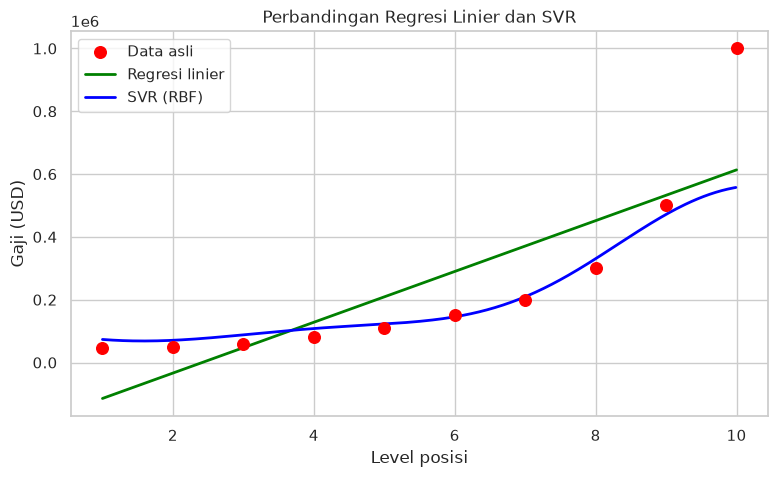

In [15]:
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color="red", s=70, label="Data asli", zorder=3)
plt.plot(X, linreg.predict(X), color="green", linewidth=2, label="Regresi linier")
plt.plot(X_grid, y_grid, color="blue", linewidth=2, label="SVR (RBF)")
plt.title("Perbandingan Regresi Linier dan SVR")
plt.xlabel("Level posisi")
plt.ylabel("Gaji (USD)")
plt.legend()
plt.show()

### 9. Interpretasi dan kesimpulan

1. Hubungan level posisi dan gaji bersifat **non-linear**, sehingga garis lurus regresi linier kurang tepat.
2. SVR dengan kernel RBF mampu mengikuti pola tersebut dengan R² sekitar **0,752**, lebih tinggi daripada regresi linier sekitar **0,669**.
3. Prediksi gaji untuk level 6,5 adalah sekitar **USD 170.370**, berada di antara gaji Region Manager (level 6) dan Partner (level 7).
4. Feature scaling sangat penting pada SVR karena model berbasis jarak; tanpa scaling, fitur dengan skala besar akan mendominasi.
5. Evaluasi masih bersifat *in-sample* karena keterbatasan jumlah data. Untuk klaim performa yang lebih kuat, diperlukan data uji tambahan atau validasi silang.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS06 – Regresi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi
- `scikit-learn` – Support Vector Regression. https://scikit-learn.org/stable/modules/svm.html#svm-regression
- `scikit-learn` – Preprocessing: StandardScaler. https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling
- Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing*, 14(3), 199–222.